### LIRARIES & SET UP AND IMPORT OF DATASET_LOADER (FOR CITYSCAPES DATASET)

In [1]:
# Standard libraries
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random
from collections import OrderedDict

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Detectron2
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.modeling import build_model
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.structures import Boxes, ImageList, Instances


# PROJECT IMPORTS (dataset_loader from data/)

# Add project root to Python path
project_root = Path.cwd().parent  # Go up from notebooks/ to INSEG_PRO/
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import your custom loader using the correct module path
from data.dataset_loader import (
    setup_dataset,
    register_cityscapes_dataset,
    CITYSCAPES_THING_CLASSES,
    CITYSCAPES_THING_COLORS
)

print("✅ All imports successful")
print(f"   Project root: {project_root}")
print(f"   Dataset loader: {project_root / 'data' / 'dataset_loader.py'}")
print(f"\n   PyTorch version: {torch.__version__}")
print(f"   CUDA available: {torch.cuda.is_available()}")
print(f"   Cityscapes classes: {len(CITYSCAPES_THING_CLASSES)}")

/home/rachidjunior/miniconda3/envs/inseg_proj/lib/python3.10/site-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


✅ All imports successful
   Project root: /home/rachidjunior/VS_Code/INSEG_PRO
   Dataset loader: /home/rachidjunior/VS_Code/INSEG_PRO/data/dataset_loader.py

   PyTorch version: 2.10.0+cpu
   CUDA available: False
   Cityscapes classes: 8


### LOAD MODEL & PREPARE INPUT

In [2]:
# ============================================
# LOAD DATASET
# ============================================

# Use the setup_dataset function (easiest method)
dataset_name, dataset_dicts, metadata = setup_dataset(
    use_cityscapes=True,
    split="val"
)

print(f"✅ Dataset loaded: {len(dataset_dicts)} images")
print(f"   Dataset: {dataset_name}")
print(f"   Classes: {metadata.thing_classes}")

# Select a test image (choose one with many objects)
sample = random.choice(dataset_dicts)
image_path = sample["file_name"]
original_image = cv2.imread(image_path)

print(f"\n📷 Test Image:")
print(f"   Path: {Path(image_path).name}")
print(f"   Size: {original_image.shape}")
print(f"   Ground truth objects: {len(sample['annotations'])}")

# ============================================
# BUILD MODEL
# ============================================

# Create configuration
cfg = get_cfg()
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
)
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.DEVICE = "cpu"  # Change to "cuda" if GPU available

print(f"\n🔧 Model Configuration:")
print(f"   Architecture: Mask R-CNN")
print(f"   Backbone: ResNet-50 + FPN")
print(f"   Device: {cfg.MODEL.DEVICE}")

# Build model
model = build_model(cfg)
model.eval()  # Set to evaluation mode

# Load pretrained weights
checkpointer = DetectionCheckpointer(model)
checkpointer.load(cfg.MODEL.WEIGHTS)

print(f"\n✅ Model built and weights loaded")
print(f"   Total parameters: {sum(p.numel() for p in model.parameters()):,}")

# ============================================
# PREPARE INPUT
# ============================================

height, width = original_image.shape[:2]

# Detectron2 expects a list of dicts
inputs = [{
    "image": torch.as_tensor(original_image.astype("float32").transpose(2, 0, 1)),
    "height": height,
    "width": width,
}]

print(f"\n📊 Input prepared:")
print(f"   Tensor shape: {inputs[0]['image'].shape}")
print(f"   Format: (channels, height, width)")

✅ Dataset loaded: 492 images
   Dataset: cityscapes_custom_val
   Classes: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

📷 Test Image:
   Path: frankfurt_000001_028854_leftImg8bit.png
   Size: (1024, 2048, 3)
   Ground truth objects: 19

🔧 Model Configuration:
   Architecture: Mask R-CNN
   Backbone: ResNet-50 + FPN
   Device: cpu

✅ Model built and weights loaded
   Total parameters: 44,343,216

📊 Input prepared:
   Tensor shape: torch.Size([3, 1024, 2048])
   Format: (channels, height, width)


### VISUALIZE INPUT & MODEL ARCHITECTURE

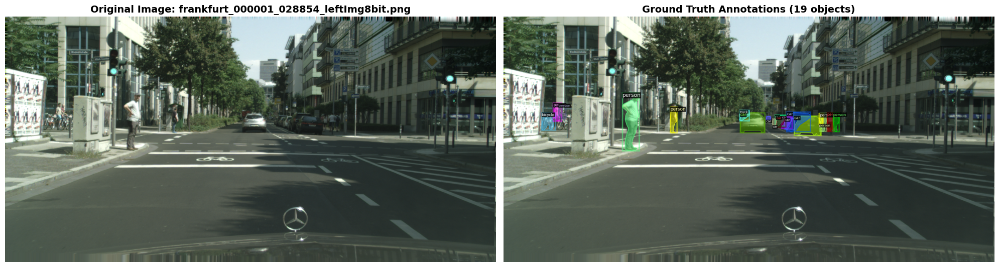


📋 Ground Truth Details:
Class           Count    Avg Area    
----------------------------------------
person          8              3904 px²
car             9              3830 px²
truck           1              1720 px²
bicycle         1              4104 px²

MODEL ARCHITECTURE BREAKDOWN

📦 Top-level components:
   • backbone: FPN
   • proposal_generator: RPN
   • roi_heads: StandardROIHeads

🧠 Backbone structure (ResNet-50 + FPN):
   • fpn_lateral2: Conv2d
   • fpn_output2: Conv2d
   • fpn_lateral3: Conv2d
   • fpn_output3: Conv2d
   • fpn_lateral4: Conv2d
   • fpn_output4: Conv2d
   • fpn_lateral5: Conv2d
   • fpn_output5: Conv2d
   • top_block: LastLevelMaxPool
   • bottom_up: ResNet

📍 Proposal Generator (RPN - Region Proposal Network):
   • rpn_head: StandardRPNHead
   • anchor_generator: DefaultAnchorGenerator

🎯 ROI Heads (Region of Interest):
   • box_pooler: ROIPooler
   • box_head: FastRCNNConvFCHead
   • box_predictor: FastRCNNOutputLayers
   • mask_pooler: ROIPooler
  

In [3]:
# VISUALIZE INPUT IMAGE + GROUND TRUTH

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Left: Original image
axes[0].imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
axes[0].axis('off')
axes[0].set_title(f"Original Image: {Path(image_path).name}", fontsize=14, fontweight='bold')

# Right: Image with ground truth annotations
visualizer = Visualizer(
    cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB),
    metadata=metadata,
    scale=0.8,
    instance_mode=ColorMode.IMAGE
)
vis_output = visualizer.draw_dataset_dict(sample)

axes[1].imshow(vis_output.get_image())
axes[1].axis('off')
axes[1].set_title(f"Ground Truth Annotations ({len(sample['annotations'])} objects)", 
                  fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Print detailed annotation info
print("\n📋 Ground Truth Details:")
print("="*80)

from collections import Counter
gt_classes = [ann['category_id'] for ann in sample['annotations']]
gt_class_names = [metadata.thing_classes[cid] for cid in gt_classes]
class_counts = Counter(gt_class_names)

print(f"{'Class':<15} {'Count':<8} {'Avg Area':<12}")
print("-"*40)

for cls_name in metadata.thing_classes:
    count = class_counts.get(cls_name, 0)
    if count > 0:
        # Calculate average area for this class
        areas = [ann['area'] for ann in sample['annotations'] 
                if metadata.thing_classes[ann['category_id']] == cls_name]
        avg_area = np.mean(areas)
        print(f"{cls_name:<15} {count:<8} {avg_area:>10.0f} px²")

print("\n" + "="*80)
print("MODEL ARCHITECTURE BREAKDOWN")
print("="*80)

# Print model structure
print("\n📦 Top-level components:")
for name, module in model.named_children():
    print(f"   • {name}: {module.__class__.__name__}")

print("\n🧠 Backbone structure (ResNet-50 + FPN):")
for name, module in model.backbone.named_children():
    print(f"   • {name}: {module.__class__.__name__}")
    if hasattr(module, '__len__'):
        print(f"      └─ Contains {len(module)} layers")

print("\n📍 Proposal Generator (RPN - Region Proposal Network):")
for name, module in model.proposal_generator.named_children():
    print(f"   • {name}: {module.__class__.__name__}")

print("\n🎯 ROI Heads (Region of Interest):")
for name, module in model.roi_heads.named_children():
    print(f"   • {name}: {module.__class__.__name__}")

# Count parameters per component
def count_parameters(module):
    return sum(p.numel() for p in module.parameters())

print("\n📊 Parameter count by component:")
print("-"*50)
backbone_params = count_parameters(model.backbone)
rpn_params = count_parameters(model.proposal_generator)
roi_params = count_parameters(model.roi_heads)
total_params = count_parameters(model)

print(f"   Backbone (ResNet-50+FPN):  {backbone_params:>12,} params ({backbone_params/total_params*100:>5.1f}%)")
print(f"   RPN (Proposals):           {rpn_params:>12,} params ({rpn_params/total_params*100:>5.1f}%)")
print(f"   ROI Heads (Detection+Seg): {roi_params:>12,} params ({roi_params/total_params*100:>5.1f}%)")
print("-"*50)
print(f"   TOTAL:                     {total_params:>12,} params (100.0%)")

# Memory estimate
param_size_mb = (total_params * 4) / (1024**2)  # 4 bytes per float32
print(f"\n💾 Model size (weights only): ~{param_size_mb:.1f} MB")

print("\n✅ Visualization and architecture analysis complete")

### EXTRACT & VISUALIZE BLACKBONE FEATURES

BACKBONE FEATURE EXTRACTION


/home/rachidjunior/miniconda3/envs/inseg_proj/lib/python3.10/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W0207 17:18:17.187000 16471 site-packages/torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


✅ Features extracted from ResNet stages

res2:
   Shape: torch.Size([256, 256, 512])
   Channels: 256
   Spatial size: 256x512
   Receptive field: ~4 pixels

res3:
   Shape: torch.Size([512, 128, 256])
   Channels: 512
   Spatial size: 128x256
   Receptive field: ~8 pixels

res4:
   Shape: torch.Size([1024, 64, 128])
   Channels: 1024
   Spatial size: 64x128
   Receptive field: ~16 pixels

res5:
   Shape: torch.Size([2048, 32, 64])
   Channels: 2048
   Spatial size: 32x64
   Receptive field: ~32 pixels


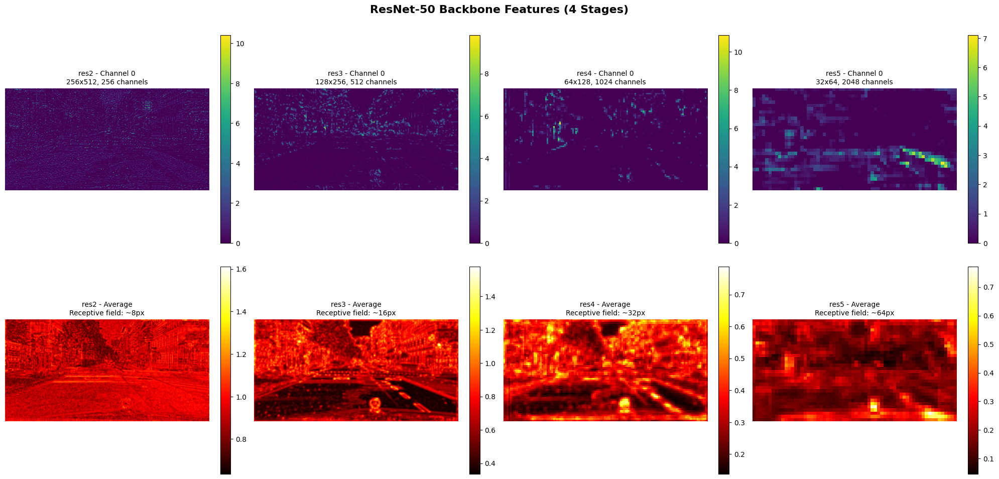


✅ Backbone features visualized


In [4]:

print("="*80)
print("BACKBONE FEATURE EXTRACTION")
print("="*80)

# Dictionary to store features
features = {}

# Define hook functions for each ResNet stage
def get_hook(name):
    def hook(module, input, output):
        features[name] = output.detach()
    return hook

# Register hooks for ResNet stages
hooks = []
hooks.append(model.backbone.bottom_up.res2.register_forward_hook(get_hook('res2')))
hooks.append(model.backbone.bottom_up.res3.register_forward_hook(get_hook('res3')))
hooks.append(model.backbone.bottom_up.res4.register_forward_hook(get_hook('res4')))
hooks.append(model.backbone.bottom_up.res5.register_forward_hook(get_hook('res5')))

# Run forward pass
with torch.no_grad():
    _ = model(inputs)

# Remove hooks (cleanup)
for hook in hooks:
    hook.remove()

print("✅ Features extracted from ResNet stages")

# Visualize features from each stage
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

stage_names = ['res2', 'res3', 'res4', 'res5']

for idx, stage_name in enumerate(stage_names):
    feature_map = features[stage_name][0]  # First image in batch
    
    # Get info
    num_channels = feature_map.shape[0]
    height = feature_map.shape[1]
    width = feature_map.shape[2]
    
    print(f"\n{stage_name}:")
    print(f"   Shape: {feature_map.shape}")
    print(f"   Channels: {num_channels}")
    print(f"   Spatial size: {height}x{width}")
    print(f"   Receptive field: ~{2**(idx+2)} pixels")
    
    # Visualize first channel
    ax1 = axes[0, idx]
    feature_img = feature_map[0].cpu().numpy()
    im1 = ax1.imshow(feature_img, cmap='viridis')
    ax1.set_title(f"{stage_name} - Channel 0\n{height}x{width}, {num_channels} channels", fontsize=10)
    ax1.axis('off')
    plt.colorbar(im1, ax=ax1, fraction=0.046)
    
    # Visualize average across all channels
    ax2 = axes[1, idx]
    feature_avg = feature_map.mean(dim=0).cpu().numpy()
    im2 = ax2.imshow(feature_avg, cmap='hot')
    ax2.set_title(f"{stage_name} - Average\nReceptive field: ~{2**(idx+3)}px", fontsize=10)
    ax2.axis('off')
    plt.colorbar(im2, ax=ax2, fraction=0.046)

plt.suptitle("ResNet-50 Backbone Features (4 Stages)", fontsize=16, fontweight='bold')
plt.tight_layout()

# Save
output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)
plt.savefig(output_dir / "backbone_features.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Backbone features visualized")

### VISUALIZE FEATURE PYRAMID NETWORK

FEATURE PYRAMID NETWORK (FPN)
✅ FPN features extracted

P2:
   Shape: torch.Size([256, 256, 512])
   Channels: 256 (always 256 in FPN)
   Spatial size: 256x512
   Stride: 4 (1/4 of original)

P3:
   Shape: torch.Size([256, 128, 256])
   Channels: 256 (always 256 in FPN)
   Spatial size: 128x256
   Stride: 8 (1/8 of original)

P4:
   Shape: torch.Size([256, 64, 128])
   Channels: 256 (always 256 in FPN)
   Spatial size: 64x128
   Stride: 16 (1/16 of original)

P5:
   Shape: torch.Size([256, 32, 64])
   Channels: 256 (always 256 in FPN)
   Spatial size: 32x64
   Stride: 32 (1/32 of original)

P6:
   Shape: torch.Size([256, 16, 32])
   Channels: 256 (always 256 in FPN)
   Spatial size: 16x32
   Stride: 64 (1/64 of original)


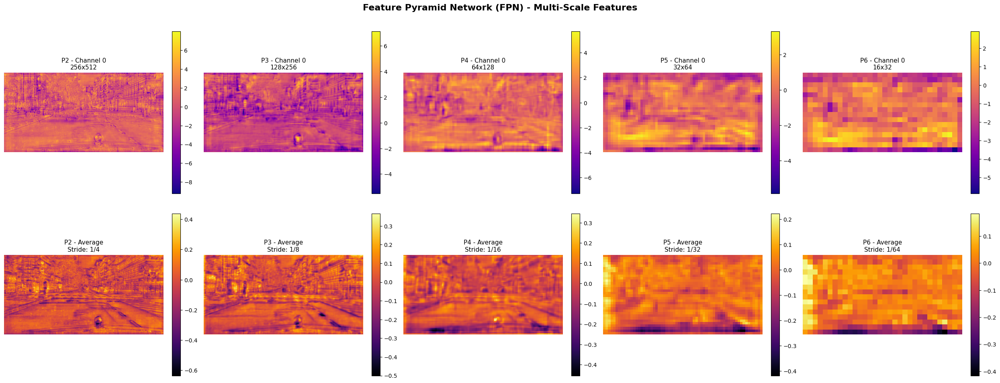


💡 FPN Insight:
   • All FPN levels have same channel count (256)
   • Different spatial resolutions capture different object scales
   • P2 (large) → detects small objects (pedestrians, bicycles)
   • P6 (small) → detects large objects (buses, trucks)
   • RPN and ROI heads use ALL pyramid levels!

✅ FPN features visualized


In [5]:

print("="*80)
print("FEATURE PYRAMID NETWORK (FPN)")
print("="*80)

# FPN creates 5 pyramid levels: P2, P3, P4, P5, P6
# P2 = High resolution (for small objects)
# P6 = Low resolution (for large objects)

fpn_features = {}

# Register hooks for FPN outputs
hooks = []
for i in range(2, 7):  # P2 through P6
    layer_name = f'p{i}'
    # FPN outputs are accessed differently
    hooks.append(
        model.backbone.register_forward_hook(
            lambda m, inp, out, name=layer_name: fpn_features.update({name: out[name]})
        )
    )

# Run forward pass
with torch.no_grad():
    _ = model(inputs)

# Remove hooks
for hook in hooks:
    hook.remove()

print("✅ FPN features extracted")

# Visualize all FPN levels
fig, axes = plt.subplots(2, 5, figsize=(25, 10))

pyramid_levels = ['p2', 'p3', 'p4', 'p5', 'p6']

for idx, level_name in enumerate(pyramid_levels):
    feature_map = fpn_features[level_name][0]  # First image
    
    # Info
    num_channels = feature_map.shape[0]
    height = feature_map.shape[1]
    width = feature_map.shape[2]
    
    print(f"\n{level_name.upper()}:")
    print(f"   Shape: {feature_map.shape}")
    print(f"   Channels: {num_channels} (always 256 in FPN)")
    print(f"   Spatial size: {height}x{width}")
    print(f"   Stride: {2**(idx+2)} (1/{2**(idx+2)} of original)")
    
    # Visualize first channel
    ax1 = axes[0, idx]
    feature_img = feature_map[0].cpu().numpy()
    im1 = ax1.imshow(feature_img, cmap='plasma')
    ax1.set_title(f"{level_name.upper()} - Channel 0\n{height}x{width}", fontsize=11)
    ax1.axis('off')
    plt.colorbar(im1, ax=ax1, fraction=0.046)
    
    # Visualize average
    ax2 = axes[1, idx]
    feature_avg = feature_map.mean(dim=0).cpu().numpy()
    im2 = ax2.imshow(feature_avg, cmap='inferno')
    ax2.set_title(f"{level_name.upper()} - Average\nStride: 1/{2**(idx+2)}", fontsize=11)
    ax2.axis('off')
    plt.colorbar(im2, ax=ax2, fraction=0.046)

plt.suptitle("Feature Pyramid Network (FPN) - Multi-Scale Features", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(output_dir / "fpn_features.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n💡 FPN Insight:")
print("   • All FPN levels have same channel count (256)")
print("   • Different spatial resolutions capture different object scales")
print("   • P2 (large) → detects small objects (pedestrians, bicycles)")
print("   • P6 (small) → detects large objects (buses, trucks)")
print("   • RPN and ROI heads use ALL pyramid levels!")

print("\n✅ FPN features visualized")

### VISUALIZE REGION OF PROPOSAL

REGION PROPOSAL NETWORK (RPN)
✅ RPN generated 1000 proposals
   Box format: (x1, y1, x2, y2)
   Objectness scores range: [-2.030, 9.812]


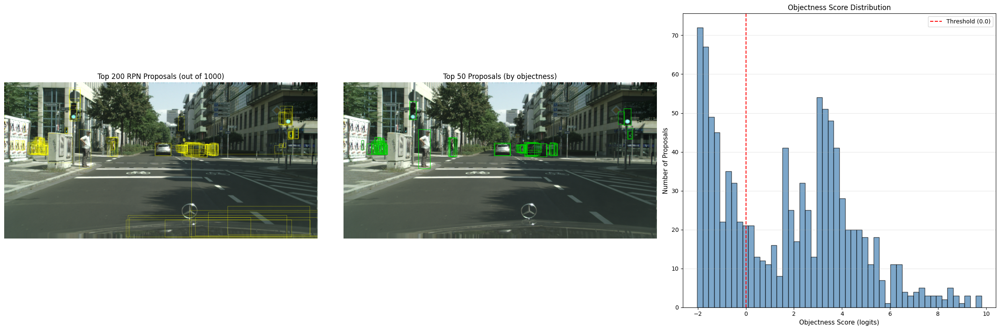


💡 RPN Insights:
   • RPN proposes ~1000 candidate boxes
   • Objectness score: How likely each box contains ANY object
   • High score ≠ correct class (that's ROI Head's job)
   • Many proposals overlap → NMS removes duplicates
   • Only top ~1000 are kept (from ~200k anchors)

✅ RPN proposals visualized


In [6]:

print("="*80)
print("REGION PROPOSAL NETWORK (RPN)")
print("="*80)

# RPN outputs proposals (candidate boxes)
# Let's capture them

proposals = None

def rpn_hook(module, input, output):
    global proposals
    proposals = output[0]  # List of Instances, one per image

# Register hook on RPN
hook = model.proposal_generator.register_forward_hook(rpn_hook)

# Run forward pass
with torch.no_grad():
    _ = model(inputs)

hook.remove()

# Extract proposals for first image
image_proposals = proposals[0]
proposal_boxes = image_proposals.proposal_boxes.tensor.cpu().numpy()
objectness_scores = image_proposals.objectness_logits.cpu().numpy()

num_proposals = len(proposal_boxes)

print(f"✅ RPN generated {num_proposals} proposals")
print(f"   Box format: (x1, y1, x2, y2)")
print(f"   Objectness scores range: [{objectness_scores.min():.3f}, {objectness_scores.max():.3f}]")

# Sort by objectness score
sorted_indices = np.argsort(objectness_scores)[::-1]  # Descending

# Visualize proposals
fig, axes = plt.subplots(1, 3, figsize=(24, 8))

# 1. All proposals
ax1 = axes[0]
img_copy = original_image.copy()
for box in proposal_boxes[:200]:  # Show top 200 to avoid clutter
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(img_copy, (x1, y1), (x2, y2), (0, 255, 255), 1)

ax1.imshow(cv2.cvtColor(img_copy, cv2.COLOR_BGR2RGB))
ax1.set_title(f"Top 200 RPN Proposals (out of {num_proposals})", fontsize=12)
ax1.axis('off')

# 2. Top 50 high-confidence proposals
ax2 = axes[1]
img_copy2 = original_image.copy()
for idx in sorted_indices[:50]:
    box = proposal_boxes[idx]
    score = objectness_scores[idx]
    x1, y1, x2, y2 = box.astype(int)
    # Color by confidence: green = high, red = low
    color = (0, int(255 * (score - objectness_scores.min()) / (objectness_scores.max() - objectness_scores.min())), 0)
    cv2.rectangle(img_copy2, (x1, y1), (x2, y2), color, 2)

ax2.imshow(cv2.cvtColor(img_copy2, cv2.COLOR_BGR2RGB))
ax2.set_title("Top 50 Proposals (by objectness)", fontsize=12)
ax2.axis('off')

# 3. Objectness score distribution
ax3 = axes[2]
ax3.hist(objectness_scores, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax3.set_xlabel('Objectness Score (logits)', fontsize=11)
ax3.set_ylabel('Number of Proposals', fontsize=11)
ax3.set_title('Objectness Score Distribution', fontsize=12)
ax3.grid(axis='y', alpha=0.3)
ax3.axvline(0, color='red', linestyle='--', label='Threshold (0.0)')
ax3.legend()

plt.tight_layout()
plt.savefig(output_dir / "rpn_proposals.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n💡 RPN Insights:")
print(f"   • RPN proposes ~{num_proposals} candidate boxes")
print(f"   • Objectness score: How likely each box contains ANY object")
print(f"   • High score ≠ correct class (that's ROI Head's job)")
print(f"   • Many proposals overlap → NMS removes duplicates")
print(f"   • Only top ~1000 are kept (from ~200k anchors)")

print("\n✅ RPN proposals visualized")

### VISUALIZE ANCHOR BOXES

ANCHOR BOXES
✅ Generated 393,216 anchor boxes
   Number of anchor types per location: [3, 3, 3, 3, 3]
   Pyramid levels: P2, P3, P4, P5, P6

📊 Anchors per pyramid level:
   P2: 256x512 positions × 3 anchors = 393,216 total
   P3: 128x256 positions × 3 anchors = 98,304 total
   P4: 64x128 positions × 3 anchors = 24,576 total
   P5: 32x64 positions × 3 anchors = 6,144 total
   P6: 16x32 positions × 3 anchors = 1,536 total


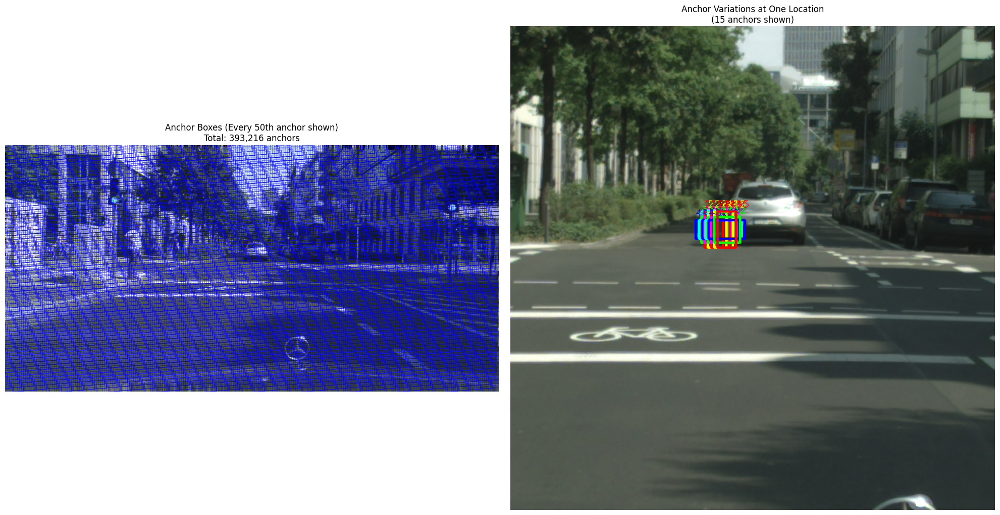


💡 Anchor Insights:
   • Anchors are PRE-DEFINED boxes (not learned)
   • Different sizes handle different object scales
   • Different ratios handle different object shapes (tall, wide, square)
   • RPN's job: Classify anchors (object/not) + Adjust them (regression)
   • Total anchors: 393,216, but only top ~1000 become proposals

✅ Anchor boxes visualized


In [7]:
print("="*80)
print("ANCHOR BOXES")
print("="*80)

# Get anchor generator
anchor_generator = model.proposal_generator.anchor_generator

# Generate anchors for the input image
from detectron2.structures import ImageList

# Prepare image list (Detectron2 format)
images = ImageList.from_tensors([inputs[0]["image"]], size_divisibility=32)

# Get FPN features (needed to know feature map sizes)
with torch.no_grad():
    features_dict = model.backbone(images.tensor)

features_list = [features_dict[f] for f in ['p2', 'p3', 'p4', 'p5', 'p6']]

# Generate anchors
anchors = anchor_generator(features_list)
# anchors is a list of Boxes objects, one per image

all_anchors = anchors[0]  # Get anchors for first image
anchor_boxes = all_anchors.tensor.cpu().numpy()

total_anchors = len(anchor_boxes)

print(f"✅ Generated {total_anchors:,} anchor boxes")
print(f"   Number of anchor types per location: {anchor_generator.num_anchors}")
print(f"   Pyramid levels: P2, P3, P4, P5, P6")

# Analyze anchors per level
print(f"\n📊 Anchors per pyramid level:")
for i, level in enumerate(['P2', 'P3', 'P4', 'P5', 'P6']):
    # Feature map size
    feat_h, feat_w = features_list[i].shape[2], features_list[i].shape[3]
    num_positions = feat_h * feat_w
    num_anchors_per_pos = anchor_generator.num_anchors[i]
    total_level_anchors = num_positions * num_anchors_per_pos
    
    print(f"   {level}: {feat_h}x{feat_w} positions × {num_anchors_per_pos} anchors = {total_level_anchors:,} total")

# Visualize anchors at a specific location
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# 1. Sample anchors across the image
ax1 = axes[0]
img_copy = original_image.copy()

# Sample every 50th anchor to avoid clutter
sample_rate = 50
for idx in range(0, total_anchors, sample_rate):
    box = anchor_boxes[idx]
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(img_copy, (x1, y1), (x2, y2), (255, 0, 0), 1)

ax1.imshow(cv2.cvtColor(img_copy, cv2.COLOR_BGR2RGB))
ax1.set_title(f"Anchor Boxes (Every {sample_rate}th anchor shown)\nTotal: {total_anchors:,} anchors", fontsize=12)
ax1.axis('off')

# 2. Zoom into one location showing all anchor variations
ax2 = axes[1]

# Choose a point in the center
center_x, center_y = original_image.shape[1] // 2, original_image.shape[0] // 2

# Find anchors near this point
nearby_anchors = []
for box in anchor_boxes:
    anchor_cx = (box[0] + box[2]) / 2
    anchor_cy = (box[1] + box[3]) / 2
    if abs(anchor_cx - center_x) < 50 and abs(anchor_cy - center_y) < 50:
        nearby_anchors.append(box)
        if len(nearby_anchors) >= 15:  # Show ~15 anchors
            break

# Crop region around center
crop_size = 300
x1_crop = max(0, center_x - crop_size)
y1_crop = max(0, center_y - crop_size)
x2_crop = min(original_image.shape[1], center_x + crop_size)
y2_crop = min(original_image.shape[0], center_y + crop_size)

img_crop = original_image[y1_crop:y2_crop, x1_crop:x2_crop].copy()

# Draw nearby anchors (adjusted for crop)
colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0), (255, 0, 255), (0, 255, 255)]
for idx, box in enumerate(nearby_anchors):
    x1, y1, x2, y2 = box.astype(int)
    # Adjust coordinates for crop
    x1 -= x1_crop
    y1 -= y1_crop
    x2 -= x1_crop
    y2 -= y1_crop
    
    color = colors[idx % len(colors)]
    cv2.rectangle(img_crop, (x1, y1), (x2, y2), color, 2)
    
    # Add label with size
    w, h = box[2] - box[0], box[3] - box[1]
    label = f"{int(w)}x{int(h)}"
    cv2.putText(img_crop, label, (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)

ax2.imshow(cv2.cvtColor(img_crop, cv2.COLOR_BGR2RGB))
ax2.set_title(f"Anchor Variations at One Location\n({len(nearby_anchors)} anchors shown)", fontsize=12)
ax2.axis('off')

plt.tight_layout()
plt.savefig(output_dir / "anchor_boxes.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n💡 Anchor Insights:")
print("   • Anchors are PRE-DEFINED boxes (not learned)")
print("   • Different sizes handle different object scales")
print("   • Different ratios handle different object shapes (tall, wide, square)")
print("   • RPN's job: Classify anchors (object/not) + Adjust them (regression)")
print(f"   • Total anchors: {total_anchors:,}, but only top ~1000 become proposals")

print("\n✅ Anchor boxes visualized")

### ROI ALIGN & FEATURE EXTRACTION

ROI ALIGN - FEATURE EXTRACTION VISUALIZATION
🧹 Cleared all stale forward hooks from model
✅ Detected 27 objects
✅ Captured ROI features:
   Box pooler output: torch.Size([1000, 256, 7, 7])  (N proposals × 256ch × 7×7)
   Mask pooler output: torch.Size([27, 256, 14, 14]) (N detections × 256ch × 14×14)

📊 Visualizing top 5 detections:

   1. person       | Score: 0.999 | Box: 75x244px
   2. car          | Score: 0.993 | Box: 103x77px
   3. person       | Score: 0.991 | Box: 33x84px
   4. person       | Score: 0.986 | Box: 34x114px
   5. person       | Score: 0.985 | Box: 22x73px


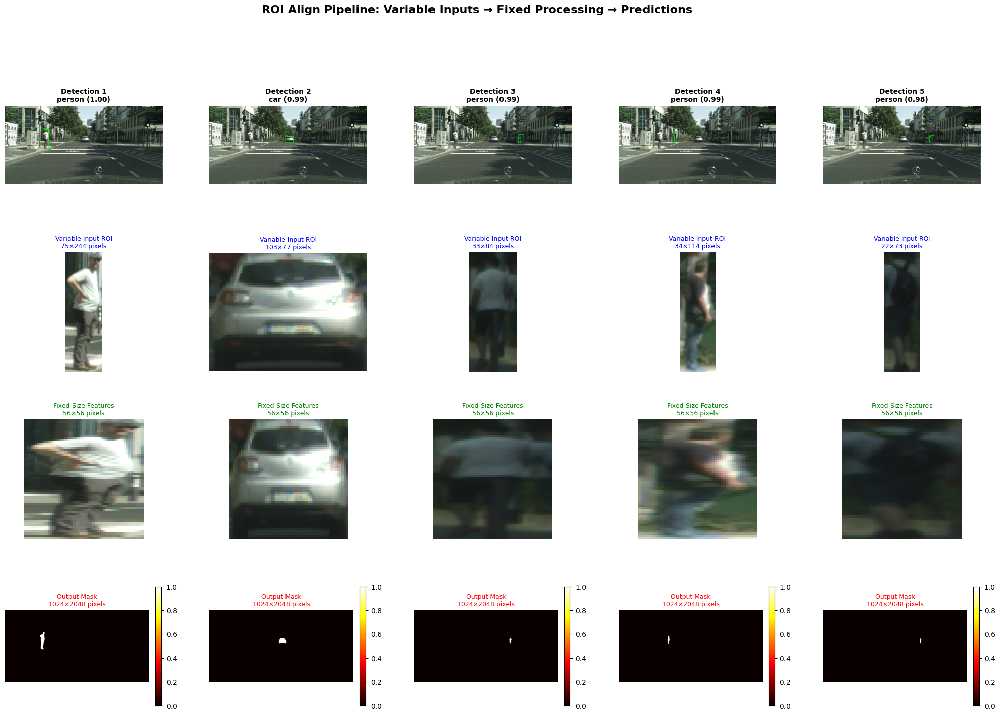


ACTUAL ROI ALIGN FEATURE MAPS (from model internals)


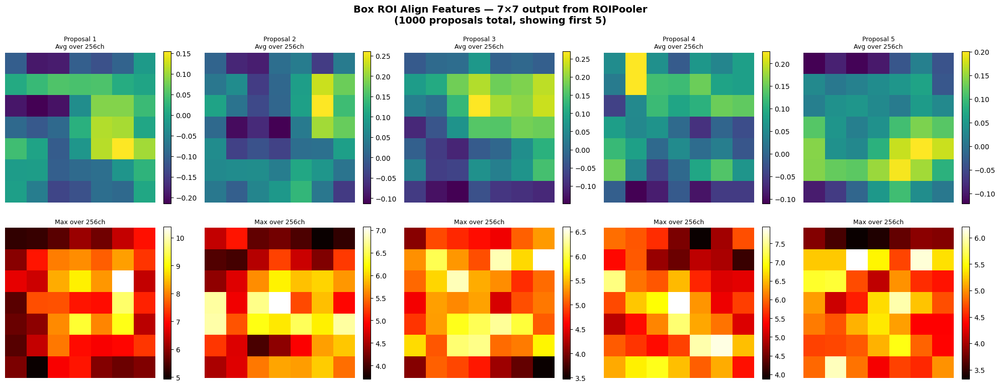


   Box ROI features: torch.Size([1000, 256, 7, 7])
   Each proposal → 256 channels × 7×7 spatial grid
   These feed into FC layers → class scores + box regression


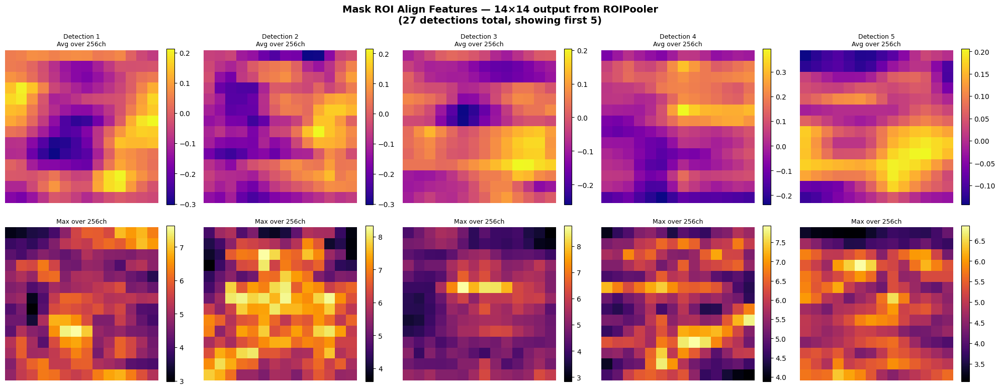


   Mask ROI features: torch.Size([27, 256, 14, 14])
   Each detection → 256 channels × 14×14 spatial grid
   These feed into 4 conv layers → deconv → 28×28 mask prediction

🔍 ROI ALIGN EXPLAINED

╔════════════════════════════════════════════════════════════════════╗
║  THE ROI ALIGN CHALLENGE & SOLUTION                               ║
╚════════════════════════════════════════════════════════════════════╝

PROBLEM:
  • Object proposals come in DIFFERENT sizes (100×50, 200×300, etc.)
  • Neural networks need FIXED-SIZE inputs
  • Simple resizing loses alignment precision

ROI ALIGN SOLUTION:

  1️⃣  LOCATE: Find proposal box coordinates (x1, y1, x2, y2)

  2️⃣  EXTRACT: Get features from appropriate FPN level
      - Small objects → P2 (high resolution)
      - Large objects → P5/P6 (low resolution)

  3️⃣  SAMPLE: Use bilinear interpolation (NOT simple resizing!)
      - Box head:  7×7 grid  → FC layers → class + refined bbox
      - Mask head: 14×14 grid → conv layers → 28×28 mask
   

In [9]:

print("="*80)
print("ROI ALIGN - FEATURE EXTRACTION VISUALIZATION")
print("="*80)

# =====================================================================
# IMPORTANT: Clear ALL stale hooks from previous runs.
# This prevents the "AttributeError: 'list' object has no attribute 'detach'"
# error caused by leftover hooks on the mask_head or other modules.
# =====================================================================
for name, module in model.named_modules():
    module._forward_hooks.clear()
    module._forward_pre_hooks.clear()

print("🧹 Cleared all stale forward hooks from model")

# =====================================================================
# STEP 1: Capture ROI Align features using hooks on the POOLERS
#   - box_pooler output: (N, 256, 7, 7) tensor  → for classification
#   - mask_pooler output: (N, 256, 14, 14) tensor → for segmentation
# We hook the poolers because they return clean tensors.
# (Hooking mask_head returns a list of Instances, which causes errors.)
# =====================================================================

roi_features = {}

def box_pooler_hook(module, input, output):
    """Capture box ROI Align features (7×7)."""
    roi_features['box'] = output.detach().cpu()

def mask_pooler_hook(module, input, output):
    """Capture mask ROI Align features (14×14)."""
    roi_features['mask'] = output.detach().cpu()

# Register hooks on the ROI poolers (NOT the heads)
hook_box = model.roi_heads.box_pooler.register_forward_hook(box_pooler_hook)
hook_mask = model.roi_heads.mask_pooler.register_forward_hook(mask_pooler_hook)

# Run inference
with torch.no_grad():
    outputs = model(inputs)

# IMMEDIATELY remove hooks after inference
hook_box.remove()
hook_mask.remove()

# =====================================================================
# STEP 2: Extract predictions
# =====================================================================
instances = outputs[0]["instances"].to("cpu")
num_detections = len(instances)

print(f"✅ Detected {num_detections} objects")
print(f"✅ Captured ROI features:")
if 'box' in roi_features:
    print(f"   Box pooler output: {roi_features['box'].shape}  (N proposals × 256ch × 7×7)")
if 'mask' in roi_features:
    print(f"   Mask pooler output: {roi_features['mask'].shape} (N detections × 256ch × 14×14)")

if num_detections == 0:
    print("⚠️  No detections found. Try lowering the confidence threshold.")
else:
    coco_metadata = MetadataCatalog.get("coco_2017_val")

    # Get top 5 detections
    top_k = min(5, num_detections)
    sorted_idx = torch.argsort(instances.scores, descending=True)[:top_k]

    print(f"\n📊 Visualizing top {top_k} detections:\n")

    # =================================================================
    # VISUALIZATION 1: ROI Align Pipeline (4 rows × top_k columns)
    #   Row 1: Full image with detection box highlighted
    #   Row 2: Cropped ROI from original image (variable size)
    #   Row 3: Simulated fixed-size ROI (what ROI Align produces)
    #   Row 4: Final predicted mask
    # =================================================================
    fig = plt.figure(figsize=(5 * top_k, 16))
    gs = fig.add_gridspec(4, top_k, hspace=0.4, wspace=0.3)

    for col_idx, det_idx in enumerate(sorted_idx):
        det_idx = det_idx.item()  # Convert tensor index to plain int
        box = instances.pred_boxes.tensor[det_idx].numpy()
        score = instances.scores[det_idx].item()
        class_id = instances.pred_classes[det_idx].item()
        mask = instances.pred_masks[det_idx].numpy()

        class_name = coco_metadata.thing_classes[class_id]
        x1, y1, x2, y2 = [int(v) for v in box]

        # Clamp to image bounds
        x1, y1 = max(0, x1), max(0, y1)
        x2 = min(original_image.shape[1], x2)
        y2 = min(original_image.shape[0], y2)
        box_width, box_height = x2 - x1, y2 - y1

        print(f"   {col_idx+1}. {class_name:12s} | Score: {score:.3f} | Box: {box_width}x{box_height}px")

        # Row 1: Full image with box
        ax1 = fig.add_subplot(gs[0, col_idx])
        img_with_box = original_image.copy()
        cv2.rectangle(img_with_box, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img_with_box, class_name, (x1, y1-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        ax1.imshow(cv2.cvtColor(img_with_box, cv2.COLOR_BGR2RGB))
        ax1.set_title(f"Detection {col_idx+1}\n{class_name} ({score:.2f})",
                      fontsize=10, fontweight='bold')
        ax1.axis('off')

        # Row 2: Cropped ROI (variable size)
        ax2 = fig.add_subplot(gs[1, col_idx])
        if box_width > 0 and box_height > 0:
            roi_crop = original_image[y1:y2, x1:x2]
            ax2.imshow(cv2.cvtColor(roi_crop, cv2.COLOR_BGR2RGB))
            ax2.set_title(f"Variable Input ROI\n{box_width}×{box_height} pixels",
                          fontsize=9, color='blue')
        else:
            ax2.text(0.5, 0.5, "Invalid ROI", ha='center', va='center')
        ax2.axis('off')

        # Row 3: Resized (simulating fixed-size output of ROI Align)
        ax3 = fig.add_subplot(gs[2, col_idx])
        if box_width > 0 and box_height > 0:
            fixed_size = 56
            roi_resized = cv2.resize(roi_crop, (fixed_size, fixed_size))
            ax3.imshow(cv2.cvtColor(roi_resized, cv2.COLOR_BGR2RGB))
            ax3.set_title(f"Fixed-Size Features\n{fixed_size}×{fixed_size} pixels",
                          fontsize=9, color='green')
        else:
            ax3.text(0.5, 0.5, "N/A", ha='center', va='center')
        ax3.axis('off')

        # Row 4: Predicted mask
        ax4 = fig.add_subplot(gs[3, col_idx])
        im = ax4.imshow(mask, cmap='hot', interpolation='bilinear')
        ax4.set_title(f"Output Mask\n{mask.shape[0]}×{mask.shape[1]} pixels",
                      fontsize=9, color='red')
        plt.colorbar(im, ax=ax4, fraction=0.046, pad=0.04)
        ax4.axis('off')

    plt.suptitle("ROI Align Pipeline: Variable Inputs → Fixed Processing → Predictions",
                 fontsize=16, fontweight='bold', y=0.98)
    plt.savefig(output_dir / "roi_align_pipeline.png", dpi=150, bbox_inches='tight')
    plt.show()

    # =================================================================
    # VISUALIZATION 2: Actual ROI Align Feature Maps from the poolers
    # =================================================================
    print("\n" + "="*80)
    print("ACTUAL ROI ALIGN FEATURE MAPS (from model internals)")
    print("="*80)

    # --- Box pooler features (7×7) ---
    if 'box' in roi_features:
        box_feats = roi_features['box']  # (N_proposals, 256, 7, 7)
        # Show features for the first few proposals
        n_show = min(5, box_feats.shape[0])

        fig, axes = plt.subplots(2, n_show, figsize=(4 * n_show, 8))
        if n_show == 1:
            axes = axes.reshape(2, 1)

        for i in range(n_show):
            feat = box_feats[i]  # (256, 7, 7)

            # Row 1: Average across channels
            avg_feat = feat.mean(dim=0).numpy()
            im1 = axes[0, i].imshow(avg_feat, cmap='viridis')
            axes[0, i].set_title(f"Proposal {i+1}\nAvg over 256ch", fontsize=9)
            axes[0, i].axis('off')
            plt.colorbar(im1, ax=axes[0, i], fraction=0.046)

            # Row 2: Max across channels
            max_feat = feat.max(dim=0)[0].numpy()
            im2 = axes[1, i].imshow(max_feat, cmap='hot')
            axes[1, i].set_title(f"Max over 256ch", fontsize=9)
            axes[1, i].axis('off')
            plt.colorbar(im2, ax=axes[1, i], fraction=0.046)

        plt.suptitle(f"Box ROI Align Features — 7×7 output from ROIPooler\n"
                     f"({box_feats.shape[0]} proposals total, showing first {n_show})",
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dir / "roi_align_box_features.png", dpi=150, bbox_inches='tight')
        plt.show()

        print(f"\n   Box ROI features: {box_feats.shape}")
        print(f"   Each proposal → 256 channels × 7×7 spatial grid")
        print(f"   These feed into FC layers → class scores + box regression")

    # --- Mask pooler features (14×14) ---
    if 'mask' in roi_features:
        mask_feats = roi_features['mask']  # (N_detections, 256, 14, 14)
        n_show = min(top_k, mask_feats.shape[0])

        fig, axes = plt.subplots(2, n_show, figsize=(4 * n_show, 8))
        if n_show == 1:
            axes = axes.reshape(2, 1)

        for i in range(n_show):
            feat = mask_feats[i]  # (256, 14, 14)

            # Row 1: Average across channels
            avg_feat = feat.mean(dim=0).numpy()
            im1 = axes[0, i].imshow(avg_feat, cmap='plasma')
            axes[0, i].set_title(f"Detection {i+1}\nAvg over 256ch", fontsize=9)
            axes[0, i].axis('off')
            plt.colorbar(im1, ax=axes[0, i], fraction=0.046)

            # Row 2: Max across channels
            max_feat = feat.max(dim=0)[0].numpy()
            im2 = axes[1, i].imshow(max_feat, cmap='inferno')
            axes[1, i].set_title(f"Max over 256ch", fontsize=9)
            axes[1, i].axis('off')
            plt.colorbar(im2, ax=axes[1, i], fraction=0.046)

        plt.suptitle(f"Mask ROI Align Features — 14×14 output from ROIPooler\n"
                     f"({mask_feats.shape[0]} detections total, showing first {n_show})",
                     fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(output_dir / "roi_align_mask_features.png", dpi=150, bbox_inches='tight')
        plt.show()

        print(f"\n   Mask ROI features: {mask_feats.shape}")
        print(f"   Each detection → 256 channels × 14×14 spatial grid")
        print(f"   These feed into 4 conv layers → deconv → 28×28 mask prediction")

    # =================================================================
    # EDUCATIONAL EXPLANATION
    # =================================================================
    print("\n" + "="*80)
    print("🔍 ROI ALIGN EXPLAINED")
    print("="*80)
    print("""
╔════════════════════════════════════════════════════════════════════╗
║  THE ROI ALIGN CHALLENGE & SOLUTION                               ║
╚════════════════════════════════════════════════════════════════════╝

PROBLEM:
  • Object proposals come in DIFFERENT sizes (100×50, 200×300, etc.)
  • Neural networks need FIXED-SIZE inputs
  • Simple resizing loses alignment precision

ROI ALIGN SOLUTION:

  1️⃣  LOCATE: Find proposal box coordinates (x1, y1, x2, y2)

  2️⃣  EXTRACT: Get features from appropriate FPN level
      - Small objects → P2 (high resolution)
      - Large objects → P5/P6 (low resolution)

  3️⃣  SAMPLE: Use bilinear interpolation (NOT simple resizing!)
      - Box head:  7×7 grid  → FC layers → class + refined bbox
      - Mask head: 14×14 grid → conv layers → 28×28 mask
      - Samples at exact floating-point locations (no rounding!)

  4️⃣  PROCESS: Feed to detection/segmentation heads

KEY ADVANTAGES over old ROI Pooling:
  ✓ No quantization errors
  ✓ Better alignment for small objects
  ✓ ~10-50% accuracy improvement
  ✓ Handles any input size seamlessly

RESULT: All proposals → same feature size → batch processing!
    """)

    # Statistics
    boxes_np = instances.pred_boxes.tensor.numpy()
    areas = [(b[2]-b[0]) * (b[3]-b[1]) for b in boxes_np]

    print(f"📈 Detection Statistics:")
    print(f"   Total detections: {num_detections}")
    print(f"   Box size range: {min(areas)/1000:.1f}k - {max(areas)/1000:.1f}k pixels²")
    print(f"   Average confidence: {instances.scores.mean():.3f}")
    print(f"   Size variation: {max(areas)/min(areas):.1f}× difference")
    print(f"\n   → ROI Align handles ALL these sizes with the SAME network!")

print("\n✅ ROI Align visualization complete")


### Mass Head & Mask Generation

MASK HEAD - PIXEL-WISE SEGMENTATION
✅ Generated masks for 27 detections
   Mask shape per instance: (1024, 2048) (H×W)


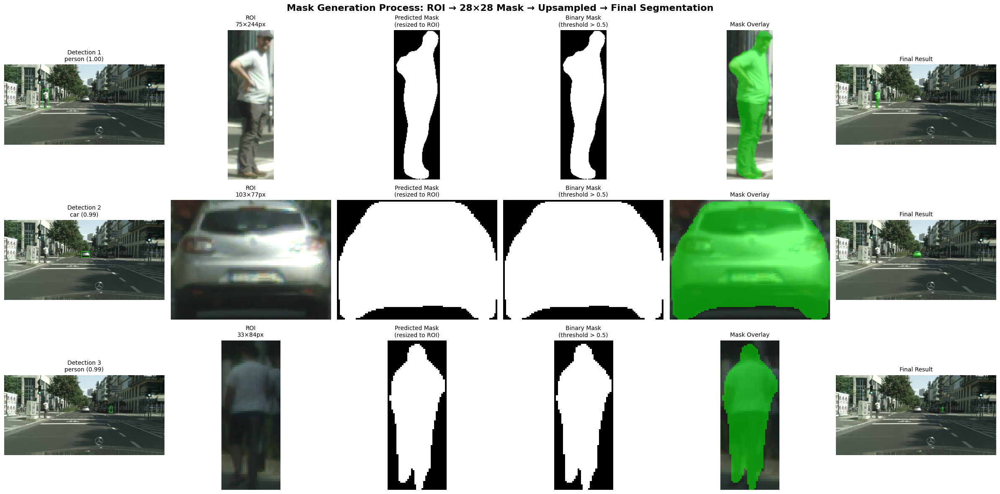


🎭 Mask Head Architecture:
   Input: ROI features (256 channels, 14×14)
   ↓
   Conv1: 256→256 channels, 3×3, ReLU
   Conv2: 256→256 channels, 3×3, ReLU
   Conv3: 256→256 channels, 3×3, ReLU
   Conv4: 256→256 channels, 3×3, ReLU
   ↓
   Deconv: 256→256 channels, 2×2, stride 2 (upsample to 28×28)
   ↓
   Conv_final: 256→80 channels, 1×1 (one mask per class)
   ↓
   Output: 80 masks of 28×28 (one per COCO class)
   
   At inference:
   → Select mask corresponding to predicted class
   → Resize 28×28 mask to box size
   → Threshold at 0.5 to get binary mask
   → Paste into full image

📊 Mask Statistics:
   person:
      Mask pixels: 9,695 / 2,097,152
      Coverage: 0.46% of image
   car:
      Mask pixels: 6,438 / 2,097,152
      Coverage: 0.31% of image
   person:
      Mask pixels: 1,578 / 2,097,152
      Coverage: 0.08% of image

✅ Mask generation visualization complete


In [10]:

print("="*80)
print("MASK HEAD - PIXEL-WISE SEGMENTATION")
print("="*80)

# The mask head takes ROI features and generates class-specific masks

if num_detections > 0:
    # Get mask predictions
    pred_masks = instances.pred_masks.numpy()
    pred_boxes = instances.pred_boxes.tensor.numpy()
    pred_classes = instances.pred_classes.numpy()
    pred_scores = instances.scores.numpy()
    
    print(f"✅ Generated masks for {num_detections} detections")
    print(f"   Mask shape per instance: {pred_masks.shape[1:]} (H×W)")
    
    # Visualize mask generation for top 3 detections
    fig, axes = plt.subplots(3, 6, figsize=(24, 12))
    
    top_k = min(3, num_detections)
    sorted_indices = np.argsort(pred_scores)[::-1][:top_k]
    
    coco_metadata = MetadataCatalog.get("coco_2017_val")
    
    for row_idx, detection_idx in enumerate(sorted_indices):
        # Get detection info
        box = pred_boxes[detection_idx]
        mask = pred_masks[detection_idx]
        class_id = pred_classes[detection_idx]
        score = pred_scores[detection_idx]
        class_name = coco_metadata.thing_classes[class_id]
        
        x1, y1, x2, y2 = box.astype(int)
        box_width = x2 - x1
        box_height = y2 - y1
        
        # Column 1: Full image with box
        ax1 = axes[row_idx, 0]
        img_with_box = original_image.copy()
        cv2.rectangle(img_with_box, (x1, y1), (x2, y2), (0, 255, 0), 3)
        ax1.imshow(cv2.cvtColor(img_with_box, cv2.COLOR_BGR2RGB))
        ax1.set_title(f"Detection {row_idx+1}\n{class_name} ({score:.2f})", fontsize=10)
        ax1.axis('off')
        
        # Column 2: ROI crop
        ax2 = axes[row_idx, 1]
        roi_crop = original_image[y1:y2, x1:x2]
        if roi_crop.size > 0:
            ax2.imshow(cv2.cvtColor(roi_crop, cv2.COLOR_BGR2RGB))
            ax2.set_title(f"ROI\n{box_width}×{box_height}px", fontsize=10)
        ax2.axis('off')
        
        # Column 3: Mask (28×28 predicted, resized to box size)
        ax3 = axes[row_idx, 2]
        mask_in_box = mask[y1:y2, x1:x2]  # Extract mask within box
        ax3.imshow(mask_in_box, cmap='gray')
        ax3.set_title(f"Predicted Mask\n(resized to ROI)", fontsize=10)
        ax3.axis('off')
        
        # Column 4: Binary mask
        ax4 = axes[row_idx, 3]
        binary_mask = (mask_in_box > 0.5).astype(np.uint8) * 255
        ax4.imshow(binary_mask, cmap='gray')
        ax4.set_title(f"Binary Mask\n(threshold > 0.5)", fontsize=10)
        ax4.axis('off')
        
        # Column 5: Mask overlay on ROI
        ax5 = axes[row_idx, 4]
        if roi_crop.size > 0 and mask_in_box.shape[0] > 0:
            # Resize mask to match ROI
            mask_resized = cv2.resize(mask_in_box.astype(np.float32), 
                                     (roi_crop.shape[1], roi_crop.shape[0]))
            
            # Create colored overlay
            overlay = roi_crop.copy()
            mask_bool = mask_resized > 0.5
            overlay[mask_bool] = overlay[mask_bool] * 0.5 + np.array([0, 255, 0]) * 0.5
            
            ax5.imshow(cv2.cvtColor(overlay.astype(np.uint8), cv2.COLOR_BGR2RGB))
            ax5.set_title("Mask Overlay", fontsize=10)
        ax5.axis('off')
        
        # Column 6: Full image with mask
        ax6 = axes[row_idx, 5]
        full_overlay = original_image.copy()
        mask_bool_full = mask > 0.5
        full_overlay[mask_bool_full] = full_overlay[mask_bool_full] * 0.6 + np.array([0, 255, 0]) * 0.4
        ax6.imshow(cv2.cvtColor(full_overlay, cv2.COLOR_BGR2RGB))
        ax6.set_title("Final Result", fontsize=10)
        ax6.axis('off')
    
    plt.suptitle("Mask Generation Process: ROI → 28×28 Mask → Upsampled → Final Segmentation", 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(output_dir / "mask_generation.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    # Explain mask head architecture
    print("\n🎭 Mask Head Architecture:")
    print("   Input: ROI features (256 channels, 14×14)")
    print("   ↓")
    print("   Conv1: 256→256 channels, 3×3, ReLU")
    print("   Conv2: 256→256 channels, 3×3, ReLU")
    print("   Conv3: 256→256 channels, 3×3, ReLU")
    print("   Conv4: 256→256 channels, 3×3, ReLU")
    print("   ↓")
    print("   Deconv: 256→256 channels, 2×2, stride 2 (upsample to 28×28)")
    print("   ↓")
    print("   Conv_final: 256→80 channels, 1×1 (one mask per class)")
    print("   ↓")
    print("   Output: 80 masks of 28×28 (one per COCO class)")
    print("   ")
    print("   At inference:")
    print("   → Select mask corresponding to predicted class")
    print("   → Resize 28×28 mask to box size")
    print("   → Threshold at 0.5 to get binary mask")
    print("   → Paste into full image")
    
    # Show mask statistics
    print("\n📊 Mask Statistics:")
    for i in sorted_indices[:top_k]:
        mask = pred_masks[i]
        class_id = pred_classes[i]
        class_name = coco_metadata.thing_classes[class_id]
        
        mask_area = mask.sum()
        total_pixels = mask.shape[0] * mask.shape[1]
        coverage = (mask_area / total_pixels) * 100
        
        print(f"   {class_name}:")
        print(f"      Mask pixels: {int(mask_area):,} / {total_pixels:,}")
        print(f"      Coverage: {coverage:.2f}% of image")
    
else:
    print("⚠️  No detections to visualize masks")

print("\n✅ Mask generation visualization complete")

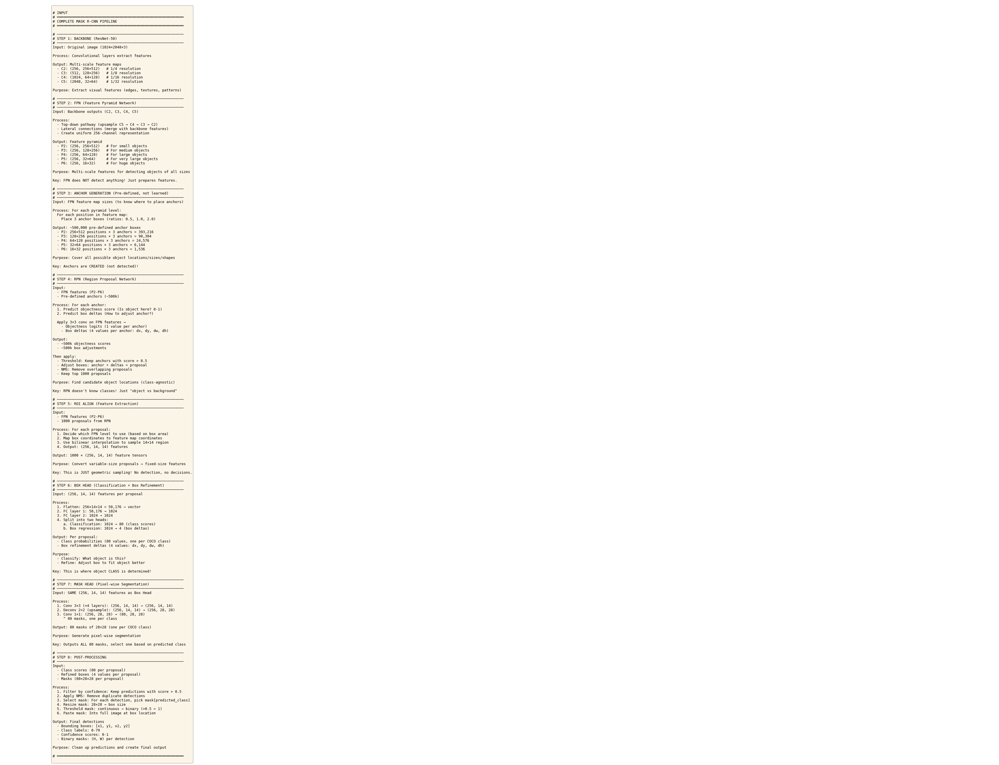


✅ Complete architecture flow visualized


In [17]:
# ═══════════════════════════════════════════════════════════
# COMPLETE PIPELINE STEP-BY-STEP
# ══════��════════════════════════════════════════════════════
fig = plt.figure(figsize=(35, 17))
flow_text = """
# INPUT
# ═══════════════════════════════════════════════════════════
# COMPLETE MASK R-CNN PIPELINE 
# ═══════════════════════════════════════════════════════════

# ───────────────────────────────────────────────────────────
# STEP 1: BACKBONE (ResNet-50)
# ───────────────────────────────────────────────────────────
Input: Original image (1024×2048×3)

Process: Convolutional layers extract features

Output: Multi-scale feature maps
  - C2: (256, 256×512)   # 1/4 resolution
  - C3: (512, 128×256)   # 1/8 resolution
  - C4: (1024, 64×128)   # 1/16 resolution
  - C5: (2048, 32×64)    # 1/32 resolution

Purpose: Extract visual features (edges, textures, patterns)

# ───────────────────────────────────────────────────────────
# STEP 2: FPN (Feature Pyramid Network)
# ───────────────────────────────────────────────────────────
Input: Backbone outputs (C2, C3, C4, C5)

Process: 
  - Top-down pathway (upsample C5 → C4 → C3 → C2)
  - Lateral connections (merge with backbone features)
  - Create uniform 256-channel representation

Output: Feature pyramid
  - P2: (256, 256×512)   # For small objects
  - P3: (256, 128×256)   # For medium objects
  - P4: (256, 64×128)    # For large objects
  - P5: (256, 32×64)     # For very large objects
  - P6: (256, 16×32)     # For huge objects

Purpose: Multi-scale features for detecting objects of all sizes

Key: FPN does NOT detect anything! Just prepares features.

# ───────────────────────────────────────────────────────────
# STEP 3: ANCHOR GENERATION (Pre-defined, not learned)
# ───────────────────────────────────────────────────────────
Input: FPN feature map sizes (to know where to place anchors)

Process: For each pyramid level:
  For each position in feature map:
    Place 3 anchor boxes (ratios: 0.5, 1.0, 2.0)

Output: ~500,000 pre-defined anchor boxes
  - P2: 256×512 positions × 3 anchors = 393,216
  - P3: 128×256 positions × 3 anchors = 98,304
  - P4: 64×128 positions × 3 anchors = 24,576
  - P5: 32×64 positions × 3 anchors = 6,144
  - P6: 16×32 positions × 3 anchors = 1,536

Purpose: Cover all possible object locations/sizes/shapes

Key: Anchors are CREATED (not detected)!

# ───────────────────────────────────────────────────────────
# STEP 4: RPN (Region Proposal Network)
# ───────────────────────────────────────────────────────────
Input: 
  - FPN features (P2-P6)
  - Pre-defined anchors (~500k)

Process: For each anchor:
  1. Predict objectness score (Is object here? 0-1)
  2. Predict box deltas (How to adjust anchor?)
  
  Apply 3×3 conv on FPN features → 
    - Objectness logits (1 value per anchor)
    - Box deltas (4 values per anchor: dx, dy, dw, dh)

Output: 
  - ~500k objectness scores
  - ~500k box adjustments

Then apply:
  - Threshold: Keep anchors with score > 0.5
  - Adjust boxes: anchor + deltas = proposal
  - NMS: Remove overlapping proposals
  - Keep top 1000 proposals

Purpose: Find candidate object locations (class-agnostic)

Key: RPN doesn't know classes! Just "object vs background"

# ───────────────────────────────────────────────────────────
# STEP 5: ROI ALIGN (Feature Extraction)
# ───────────────────────────────────────────────────────────
Input:
  - FPN features (P2-P6)
  - 1000 proposals from RPN

Process: For each proposal:
  1. Decide which FPN level to use (based on box area)
  2. Map box coordinates to feature map coordinates
  3. Use bilinear interpolation to sample 14×14 region
  4. Output: (256, 14, 14) features

Output: 1000 × (256, 14, 14) feature tensors

Purpose: Convert variable-size proposals → fixed-size features

Key: This is JUST geometric sampling! No detection, no decisions.

# ───────────────────────────────────────────────────────────
# STEP 6: BOX HEAD (Classification + Box Refinement)
# ───────────────────────────────────────────────────────────
Input: (256, 14, 14) features per proposal

Process:
  1. Flatten: 256×14×14 = 50,176 → vector
  2. FC layer 1: 50,176 → 1024
  3. FC layer 2: 1024 → 1024
  4. Split into two heads:
     a. Classification: 1024 → 80 (class scores)
     b. Box regression: 1024 → 4 (box deltas)

Output: Per proposal:
  - Class probabilities (80 values, one per COCO class)
  - Box refinement deltas (4 values: dx, dy, dw, dh)

Purpose: 
  - Classify: What object is this?
  - Refine: Adjust box to fit object better

Key: This is where object CLASS is determined!

# ───────────────────────────────────────────────────────────
# STEP 7: MASK HEAD (Pixel-wise Segmentation)
# ───────────────────────────────────────────────────────────
Input: SAME (256, 14, 14) features as Box Head

Process:
  1. Conv 3×3 (×4 layers): (256, 14, 14) → (256, 14, 14)
  2. Deconv 2×2 (upsample): (256, 14, 14) → (256, 28, 28)
  3. Conv 1×1: (256, 28, 28) → (80, 28, 28)
     ^ 80 masks, one per class

Output: 80 masks of 28×28 (one per COCO class)

Purpose: Generate pixel-wise segmentation

Key: Outputs ALL 80 masks, select one based on predicted class

# ───────────────────────────────────────────────────────────
# STEP 8: POST-PROCESSING
# ───────────────────────────────────────────────────────────
Input:
  - Class scores (80 per proposal)
  - Refined boxes (4 values per proposal)
  - Masks (80×28×28 per proposal)

Process:
  1. Filter by confidence: Keep predictions with score > 0.5
  2. Apply NMS: Remove duplicate detections
  3. Select mask: For each detection, pick mask[predicted_class]
  4. Resize mask: 28×28 → box size
  5. Threshold mask: continuous → binary (>0.5 = 1)
  6. Paste mask: Into full image at box location

Output: Final detections
  - Bounding boxes: [x1, y1, x2, y2]
  - Class labels: 0-79
  - Confidence scores: 0-1
  - Binary masks: (H, W) per detection

Purpose: Clean up predictions and create final output

# ═══════════════════════════════════════════════════════════
"""
ax = fig.add_subplot(111)
ax.text(0.05, 0.95, flow_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
ax.axis('off')

plt.tight_layout()
plt.savefig(output_dir / "complete_architecture_mask_generation.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Complete architecture flow visualized")

NameError: name 'outputs' is not defined

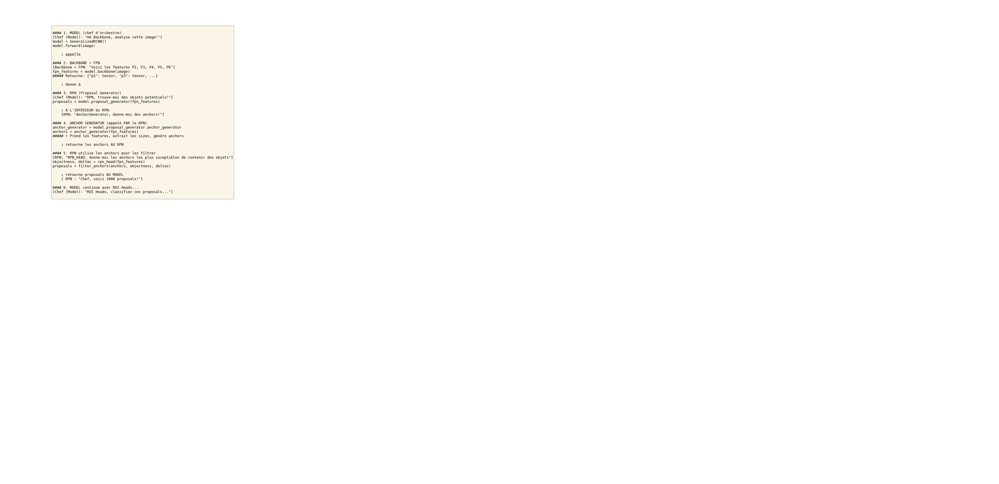

In [ ]:
import matplotlib.pyplot as plt
fig1 = plt.figure(figsize=(35, 17))
flow_text = """
#### 1. MODEL (chef d'orchestre) 
[Chef (Model): "Hé Backbone, analyse cette image!"]
model = GeneralizedRCNN()
model.forward(image)

    ↓ appelle

#### 2. BACKBONE + FPN
[Backbone + FPN: "Voici les features P2, P3, P4, P5, P6"]
fpn_features = model.backbone(image)
##### Retourne: {"p2": tensor, "p3": tensor, ...}

    ↓ donne à

#### 3. RPN (Proposal Generator)
[Chef (Model): "RPN, trouve-moi des objets potentiels!"]
proposals = model.proposal_generator(fpn_features)

    ↓ À L'INTÉRIEUR du RPN:
    [RPN: "AnchorGenerator, donne-moi des anchors!"]

#### 4. ANCHOR GENERATOR (appelé PAR le RPN)
anchor_generator = model.proposal_generator.anchor_generator
anchors = anchor_generator(fpn_features)
##### ↑ Prend les features, extrait les sizes, génère anchors

    ↓ retourne les anchors AU RPN

#### 5. RPN utilise les anchors pour les filtrer
[RPN: "RPN_HEAD, donne-moi les anchors les plus suceptibles de contenir des objets"]
objectness, deltas = rpn_head(fpn_features)
proposals = filter_anchors(anchors, objectness, deltas)

    ↓ retourne proposals AU MODEL
    [ RPN : "Chef, voici 1000 proposals!"]

#### 6. MODEL continue avec ROI Heads...
[Chef (Model): "ROI Heads, classifiez ces proposals..."]
"""
ax = fig1.add_subplot(111)
ax.text(0.05, 0.95, flow_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
ax.axis('off')

plt.tight_layout()
plt.savefig(output_dir/ "complete_architecture_mask-rcnn_in_terms_of_humans.png", dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Complete architecture flow visualized")

### SUMMARY

MASK R-CNN COMPLETE ARCHITECTURE SUMMARY


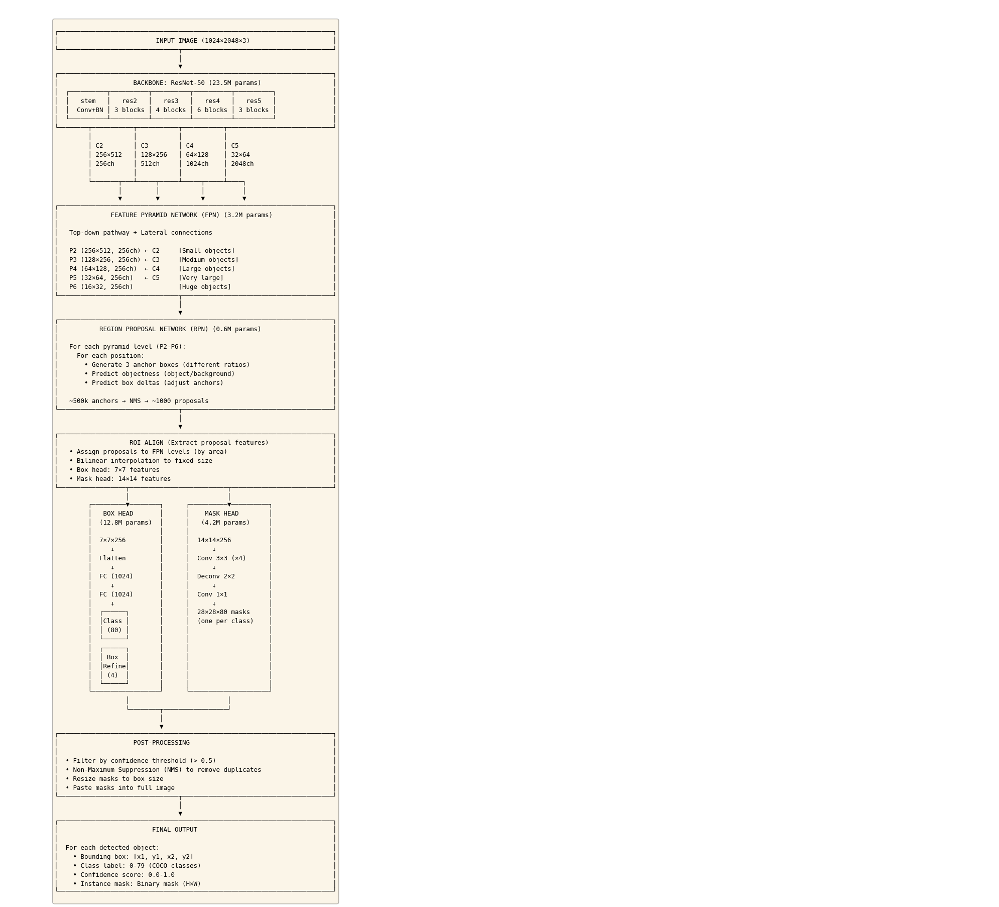


📊 MODEL STATISTICS

Parameters:
  Total:           44,343,216
  Trainable:       44,120,816
  Frozen:             222,400

Parameter breakdown:
  Backbone (ResNet-50 + FPN)       26,799,296 ( 60.4%)
  RPN                                 593,935 (  1.3%)
  ROI Heads (Box + Mask)           16,949,985 ( 38.2%)

Memory footprint (FP32):
  Model weights:   177.4 MB
  Single image:   ~500 MB (with gradients)
  Batch of 2:     ~1000 MB

Inference speed (rough estimates):
  CPU (single core):     ~2-5 seconds/image
  GPU (Tesla T4):        ~0.05-0.1 seconds/image
  GPU (RTX 3090):        ~0.03-0.05 seconds/image

🔧 KEY HYPERPARAMETERS

RPN:
  Anchor sizes:      [32, 64, 128, 256, 512]
  Anchor ratios:     [0.5, 1.0, 2.0]
  NMS threshold:     0.7
  Pre-NMS top-k:     12000 (training) / 6000 (testing)
  Post-NMS top-k:    2000 (training) / 1000 (testing)

ROI Heads:
  Box pooler:        7×7 ROI Align
  Mask pooler:       14×14 ROI Align
  Batch size (ROI):  512 (training)
  Positive fraction: 0

In [11]:
# ============================================
# CELL 10: COMPLETE ARCHITECTURE SUMMARY
# ============================================

print("="*80)
print("MASK R-CNN COMPLETE ARCHITECTURE SUMMARY")
print("="*80)

# Create comprehensive architecture diagram
fig = plt.figure(figsize=(20, 14))

# Use text-based flow diagram
flow_text = """
┌─────────────────────────────────────────────────────────────────────────┐
│                          INPUT IMAGE (1024×2048×3)                      │
└────────────────────────────────┬────────────────────────────────────────┘
                                 │
                                 ▼
┌─────────────────────────────────────────────────────────────────────────┐
│                    BACKBONE: ResNet-50 (23.5M params)                   │
│  ┌──────────┬──────────┬──────────┬──────────┬──────────┐               │
│  │   stem   │   res2   │   res3   │   res4   │   res5   │               │
│  │  Conv+BN │ 3 blocks │ 4 blocks │ 6 blocks │ 3 blocks │               │
│  └──────────┴──────────┴──────────┴──────────┴──────────┘               │
└────────┬───────────┬───────────┬───────────┬────────────────────────────┘
         │           │           │           │
         │ C2        │ C3        │ C4        │ C5
         │ 256×512   │ 128×256   │ 64×128    │ 32×64
         │ 256ch     │ 512ch     │ 1024ch    │ 2048ch
         │           │           │           │
         └───────┬───┴─────┬─────┴─────┬─────┴────┐
                 │         │           │          │
                 ▼         ▼           ▼          ▼
┌─────────────────────────────────────────────────────────────────────────┐
│              FEATURE PYRAMID NETWORK (FPN) (3.2M params)                │
│                                                                         │
│   Top-down pathway + Lateral connections                                │
│                                                                         │
│   P2 (256×512, 256ch) ← C2     [Small objects]                          │
│   P3 (128×256, 256ch) ← C3     [Medium objects]                         │
│   P4 (64×128, 256ch)  ← C4     [Large objects]                          │
│   P5 (32×64, 256ch)   ← C5     [Very large]                             │
│   P6 (16×32, 256ch)            [Huge objects]                           │
└────────────────────────────────┬────────────────────────────────────────┘
                                 │
                                 ▼
┌─────────────────────────────────────────────────────────────────────────┐
│           REGION PROPOSAL NETWORK (RPN) (0.6M params)                   │
│                                                                         │
│   For each pyramid level (P2-P6):                                       │
│     For each position:                                                  │
│       • Generate 3 anchor boxes (different ratios)                      │
│       • Predict objectness (object/background)                          │
│       • Predict box deltas (adjust anchors)                             │
│                                                                         │
│   ~500k anchors → NMS → ~1000 proposals                                 │
└────────────────────────────────┬────────────────────────────────────────┘
                                 │
                                 ▼
┌─────────────────────────────────────────────────────────────────────────┐
│                   ROI ALIGN (Extract proposal features)                 │
│   • Assign proposals to FPN levels (by area)                            │
│   • Bilinear interpolation to fixed size                                │
│   • Box head: 7×7 features                                              │
│   • Mask head: 14×14 features                                           │
└──────────────────┬──────────────────────────┬───────────────────────────┘
                   │                          │
         ┌─────────▼────────┐      ┌──────────▼──────────┐
         │   BOX HEAD       │      │    MASK HEAD        │
         │  (12.8M params)  │      │   (4.2M params)     │
         │                  │      │                     │
         │  7×7×256         │      │  14×14×256          │
         │     ↓            │      │      ↓              │
         │  Flatten         │      │  Conv 3×3 (×4)      │
         │     ↓            │      │      ↓              │
         │  FC (1024)       │      │  Deconv 2×2         │
         │     ↓            │      │      ↓              │
         │  FC (1024)       │      │  Conv 1×1           │
         │     ↓            │      │      ↓              │
         │  ┌──────┐        │      │  28×28×80 masks     │
         │  │Class │        │      │  (one per class)    │
         │  │ (80) │        │      │                     │
         │  └──────┘        │      │                     │
         │  ┌──────┐        │      │                     │
         │  │ Box  │        │      │                     │
         │  │Refine│        │      │                     │
         │  │ (4)  │        │      │                     │
         │  └──────┘        │      │                     │
         └──────────────────┘      └─────────────────────┘
                   │                          │
                   └────────┬─────────────────┘
                            │
                            ▼
┌─────────────────────────────────────────────────────────────────────────┐
│                    POST-PROCESSING                                      │
│                                                                         │
│  • Filter by confidence threshold (> 0.5)                               │
│  • Non-Maximum Suppression (NMS) to remove duplicates                   │
│  • Resize masks to box size                                             │
│  • Paste masks into full image                                          │
└────────────────────────────────┬────────────────────────────────────────┘
                                 │
                                 ▼
┌─────────────────────────────────────────────────────────────────────────┐
│                         FINAL OUTPUT                                    │
│                                                                         │
│  For each detected object:                                              │
│    • Bounding box: [x1, y1, x2, y2]                                     │
│    • Class label: 0-79 (COCO classes)                                   │
│    • Confidence score: 0.0-1.0                                          │
│    • Instance mask: Binary mask (H×W)                                   │
└─────────────────────────────────────────────────────────────────────────┘
"""

ax = fig.add_subplot(111)
ax.text(0.05, 0.95, flow_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
ax.axis('off')

plt.tight_layout()
plt.savefig(output_dir / "complete_architecture.png", dpi=150, bbox_inches='tight')
plt.show()

# Print detailed statistics
print("\n📊 MODEL STATISTICS")
print("="*80)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nParameters:")
print(f"  Total:      {total_params:>15,}")
print(f"  Trainable:  {trainable_params:>15,}")
print(f"  Frozen:     {total_params - trainable_params:>15,}")

# Breakdown by component
components = {
    'Backbone (ResNet-50 + FPN)': model.backbone,
    'RPN': model.proposal_generator,
    'ROI Heads (Box + Mask)': model.roi_heads,
}

print(f"\nParameter breakdown:")
for name, module in components.items():
    params = sum(p.numel() for p in module.parameters())
    percentage = (params / total_params) * 100
    print(f"  {name:<30} {params:>12,} ({percentage:>5.1f}%)")

# Memory estimation
print(f"\nMemory footprint (FP32):")
print(f"  Model weights:  {total_params * 4 / 1e6:>6.1f} MB")
print(f"  Single image:   ~500 MB (with gradients)")
print(f"  Batch of 2:     ~1000 MB")

# Inference speed (rough estimates)
print(f"\nInference speed (rough estimates):")
print(f"  CPU (single core):     ~2-5 seconds/image")
print(f"  GPU (Tesla T4):        ~0.05-0.1 seconds/image")
print(f"  GPU (RTX 3090):        ~0.03-0.05 seconds/image")

# Key hyperparameters
print(f"\n🔧 KEY HYPERPARAMETERS")
print("="*80)
print(f"\nRPN:")
print(f"  Anchor sizes:      {[32, 64, 128, 256, 512]}")
print(f"  Anchor ratios:     {[0.5, 1.0, 2.0]}")
print(f"  NMS threshold:     0.7")
print(f"  Pre-NMS top-k:     12000 (training) / 6000 (testing)")
print(f"  Post-NMS top-k:    2000 (training) / 1000 (testing)")

print(f"\nROI Heads:")
print(f"  Box pooler:        7×7 ROI Align")
print(f"  Mask pooler:       14×14 ROI Align")
print(f"  Batch size (ROI):  512 (training)")
print(f"  Positive fraction: 0.25")
print(f"  Score threshold:   {cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST}")
print(f"  NMS threshold:     0.5")

print(f"\n💡 KEY INSIGHTS")
print("="*80)
print("""
1. TWO-STAGE DETECTOR:
   Stage 1 (RPN): Proposes candidate boxes (~1000)
   Stage 2 (ROI): Classifies + refines boxes + generates masks

2. MULTI-SCALE DETECTION:
   FPN creates pyramid (P2-P6) for objects of all sizes
   Small objects → P2 (high resolution)
   Large objects → P6 (low resolution)

3. CLASS-AGNOSTIC RPN:
   RPN doesn't know object classes, just "object vs background"
   ROI Head does the classification (80 COCO classes)

4. CLASS-SPECIFIC MASKS:
   Mask head outputs 80 masks (one per class)
   At inference, select mask for predicted class
   Allows different mask shapes for different object types

5. ROI ALIGN INNOVATION:
   Uses bilinear interpolation (no quantization)
   Critical for pixel-accurate segmentation
   Improvement over older ROI Pooling

6. EFFICIENCY:
   ~44M parameters (relatively lightweight)
   Single forward pass for all detections
   Can process at ~10-20 FPS on modern GPUs
""")

print("\n✅ Complete architecture analysis finished!")
print(f"\n📁 All visualizations saved to: {output_dir}")
print("\nGenerated files:")
for file in sorted(output_dir.glob("*.png")):
    print(f"  • {file.name}")